# 00 · Feasibility check

**Question:** Can a simple model predict *which hours of tomorrow will be cheap*, before the
prices are known?

Tomorrow's day-ahead prices are set in an auction at 12:00 and published at around 12:45.
Many decisions (bids for that auction, shift planning) are made earlier, so the project needs a
forecast that only uses what is known **before 12:00 on the day before**.

**Go criteria, fixed in advance.** Compared with the rule of thumb *"tomorrow's prices are the
same as today's"*, the model must

1. have an error (MAE) that is at least **10 % lower**, and
2. find the **4 cheapest hours** of a day **more often**.

Data: Bundesnetzagentur | SMARD.de, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

In [1]:
from pathlib import Path

import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from emi.smard import REGION, SERIES, SmardClient

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TZ = "Europe/Berlin"
START = pd.Timestamp("2025-11-03", tz=TZ)  # one year plus one week (needed for a 7-day lag)
END = pd.Timestamp("2026-11-18", tz=TZ)  # exclusive

INK, MUTED, SURFACE = "#0b0b0b", "#898781", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "font.size": 10,
        "figure.dpi": 110,
    }
)

## 1 · Data

Hourly SMARD data for Germany/Luxembourg: the day-ahead **price** and the grid operators'
**forecasts** for tomorrow (consumption, wind + solar, solar, and the *residual load* =
consumption minus wind and solar). Downloads are cached in `data/smard_cache/`.

In [2]:
client = SmardClient(cache_dir=ROOT / "data" / "smard_cache")
keys = ["price", "fc_residual_load", "fc_load", "fc_wind_solar", "fc_solar"]
df = pd.DataFrame(
    {k: client.fetch_range(SERIES[k].filter_id, START, END, region=REGION) for k in keys}
)
df.index = df.index.tz_convert(TZ)
print(f"{len(df):,} hours, {df.index.min():%d %b %Y} to {df.index.max():%d %b %Y}")
print(f"missing values: {df.isna().sum().sum()}")

9,120 hours, 03 Nov 2025 to 17 Nov 2026
missing values: 0


## 2 · Does the forecast say anything about the price?

Each dot is one hour. The x-axis shows the **forecast residual load**, i.e. how much electricity
will still be needed from coal, gas, storage or imports after wind and solar. The orange line
is the typical (median) price at each level.

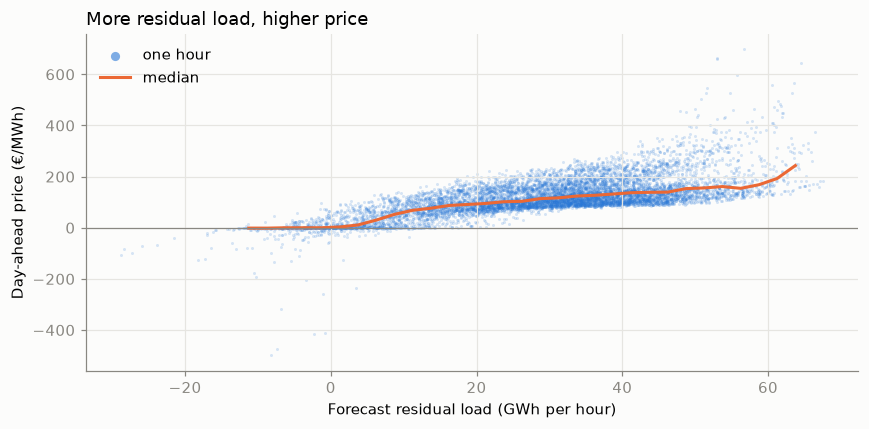

In [3]:
x = df.fc_residual_load / 1000  # MWh -> GWh
bins = np.arange(-30, 72.5, 2.5)
groups = df.price.groupby(pd.cut(x, bins), observed=True)
median = groups.median()[groups.size() >= 30]

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x, df.price, s=4, color=BLUE, alpha=0.18, linewidths=0, label="one hour")
ax.plot([iv.mid for iv in median.index], median, color=ORANGE, linewidth=2, label="median")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Forecast residual load (GWh per hour)")
ax.set_ylabel("Day-ahead price (€/MWh)")
ax.set_title("More residual load, higher price", loc="left")
legend = ax.legend(frameon=False, loc="upper left", markerscale=3)
legend.legend_handles[0].set_alpha(0.6)
fig.tight_layout()

**Takeaway:** a clear relationship. With lots of wind and solar (left) the price drops
towards zero and sometimes below; when little renewable power is expected (right) it rises.
This forecast is available before the auction, so it can be used for prediction.

## 3 · Model vs. rule of thumb

Two ways to predict tomorrow's 24 prices:

* **Yesterday:** each hour costs the same as the same hour today.
* **Model:** a linear regression (*Ridge*) using only information available before 12:00:
  * the forecasts for tomorrow (residual load, consumption, wind + solar, solar)
  * today's and last week's price for the same hour, today's average price
  * hour of the day, weekday, public holiday

**Fair test:** for each of the last 26 weeks the model is trained only on data *before* that
week and then predicts it. So it never sees the answers in advance.

In [4]:
# Model inputs (one row per hour)
X = df[["fc_residual_load", "fc_load", "fc_wind_solar", "fc_solar"]] / 1000
X = X.assign(fc_residual_load_sq=X.fc_residual_load**2 / 10)
X["price_lag24"] = df.price.shift(24)
X["price_lag168"] = df.price.shift(168)
daily_mean = df.price.groupby(df.index.date).mean()
X["prev_day_mean"] = pd.Series(df.index.date, index=df.index).map(daily_mean.shift(1)).to_numpy()
de_holidays = holidays.Germany(years=sorted({d.year for d in df.index}))
X["holiday"] = [d.date() in de_holidays for d in df.index]
X = X.join(pd.get_dummies(pd.Series(df.index.hour, index=df.index), prefix="hour"))
X = X.join(pd.get_dummies(pd.Series(df.index.day_of_week, index=df.index), prefix="dow"))
X, y = X.astype(float), df.price
usable = X.notna().all(axis=1)

# Walk-forward test: retrain every week on all earlier data
TEST_START = pd.Timestamp("2026-05-18", tz=TZ)
preds = []
for week_start in pd.date_range(TEST_START, END - pd.Timedelta(days=1), freq="7D"):
    train = usable & (df.index < week_start)
    test = usable & (df.index >= week_start) & (df.index < week_start + pd.Timedelta(days=7))
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X[train], y[train])
    preds.append(pd.Series(model.predict(X[test]), index=X.index[test]))

ev = pd.DataFrame({"actual": y, "yesterday": X.price_lag24, "model": pd.concat(preds)}).dropna()
print(f"test period: {ev.index.min():%d %b} to {ev.index.max():%d %b %Y} ({len(ev):,} hours)")

test period: 18 May to 17 Nov 2026 (4,416 hours)


### Results

For load shifting the exact price matters less than **which hours** are cheapest. Imagine a
machine that needs 4 hours a day: each method picks the 4 hours it *thinks* are cheapest, and we
look at what those hours *actually* cost.

* **MAE:** average error per hour (€/MWh), lower is better
* **Top-4 hit rate:** how many of the truly cheapest 4 hours were picked (1.0 = all four)
* **Price paid:** average actual price of the 4 picked hours (€/MWh)

*Perfect knowledge* is the best possible plan (knowing the real prices).

In [5]:
def pick_cheapest(ev, method, k=4):
    rows = []
    for _, day in ev.groupby(ev.index.date):
        best = day.actual.nsmallest(k).index
        chosen = day[method].nsmallest(k).index
        rows.append({"hit": len(best.intersection(chosen)) / k, "paid": day.actual[chosen].mean()})
    return pd.DataFrame(rows).mean()


results = pd.DataFrame(
    {
        name: {
            "MAE (€/MWh)": (ev[method] - ev.actual).abs().mean(),
            "top-4 hit rate": pick_cheapest(ev, method).hit,
            "price paid (€/MWh)": pick_cheapest(ev, method).paid,
        }
        for name, method in [
            ("yesterday", "yesterday"),
            ("model", "model"),
            ("perfect knowledge", "actual"),
        ]
    }
).T
print(f"average price of all hours (no shifting): {ev.actual.mean():.1f} €/MWh")
results.round(2)

average price of all hours (no shifting): 139.5 €/MWh


,MAE (€/MWh),top-4 hit rate,price paid (€/MWh)
yesterday,36.29,0.76,67.81
model,28.56,0.84,63.35
perfect knowledge,0.00,1.00,61.78


**Takeaway:** the model is about a fifth more accurate than *yesterday* and finds more of the
cheap hours (on average 3.4 of 4). The 4 hours it picks cost about **63 €/MWh**, less than half
the average price, and only about 1.6 €/MWh more than with perfect knowledge.

The week with the largest price swings shows why *yesterday* falls short:

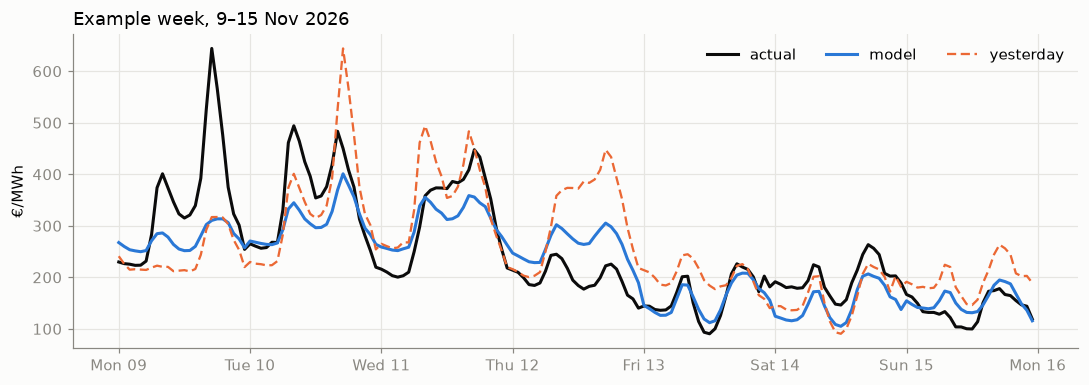

In [6]:
week = ev.loc["2026-11-09":"2026-11-15"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(week.index, week.actual, color=INK, linewidth=2, label="actual")
ax.plot(week.index, week.model, color=BLUE, linewidth=2, label="model")
ax.plot(week.index, week.yesterday, color=ORANGE, linewidth=1.5, ls=(0, (4, 2)), label="yesterday")
ax.set_ylabel("€/MWh")
ax.set_title("Example week, 9–15 Nov 2026", loc="left")
ax.legend(frameon=False, ncols=3, loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz=TZ))
fig.tight_layout()

*Yesterday* (orange) is the black line shifted by one day: Monday evening's price spike shows
up on Tuesday. The model (blue) uses tomorrow's wind, solar and demand forecasts, so it moves at
the right time, although it underestimates the highest peaks.

## 4 · Decision

In [7]:
mae_gain = 1 - results.loc["model", "MAE (€/MWh)"] / results.loc["yesterday", "MAE (€/MWh)"]
hit_gain = results.loc["model", "top-4 hit rate"] - results.loc["yesterday", "top-4 hit rate"]
print(f"1. MAE lower by {mae_gain:.0%}  (needed: at least 10 %)")
print(f"2. hit rate higher by {hit_gain:+.2f}  (needed: more than 0)")
print("Decision:", "GO" if mae_gain >= 0.10 and hit_gain > 0 else "NO-GO")

1. MAE lower by 21%  (needed: at least 10 %)
2. hit rate higher by +0.08  (needed: more than 0)
Decision: GO


**Go.** Even a simple model finds the cheap hours reliably. The project continues as planned.

**Caveats, handled in the next steps:**

* **Forecast timing:** SMARD doesn't record when a forecast was published. Whether tomorrow's
  forecasts are online before 12:00 has to be checked live.
* **Price level:** the model is on average about 20 €/MWh too low, because prices roughly
  doubled over the year (fuel and CO₂ costs, which SMARD doesn't contain). This hardly changes
  *which* hours are cheapest. A shorter training window helps; it will be chosen on day 5.
* **Small setup:** one year of data, no tuning. Good enough for a go/no-go, not a final
  result.